# 06 · What the owner sees

It's 8am on Thursday 12 December 2024 at business SP0267. The model has learned from past quotes
whose endings were known at least 45 days earlier, and it can't see anything that happened after 8am
today. I chose this morning because the different ways of ordering disagree on it; the fair
comparison across every morning is in notebook 05.

In [1]:
import sys

sys.path.insert(0, "../scripts")

import pandas as pd

from quote_followup.config import load_settings
from quote_followup.data import load_quotes

pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 100)
settings = load_settings("../config.toml")
quotes = load_quotes(settings.data_dir)

from quote_followup.board import explain, followup_board, render, with_outcomes
from quote_followup.scorers import FollowUpModel

morning = pd.Timestamp("2024-12-12 08:00")
model = FollowUpModel(settings.model).fit(quotes, morning)
board = followup_board(model, quotes, "SP0267", morning, settings.followup.daily_capacity)
print(render(board, settings.followup.daily_capacity))

Call today (top 3):
  quote     work             amount   days waiting  chance of yes  worth today  chance halves in  why
  QU013118  emergency job    $1,738   1.8           84%            $1,452       8.5 days          helps: emergency job, referred by someone; hurts: no reply for 1.8 days
  QU013170  one-off project  $2,769   0.8           45%            $1,251       4.5 days          hurts: one-off project, took 2.1 days to send, found you on their own
  QU013126  one-off project  $13,828  19.7          3%             $365         6.0 days          hurts: no reply for 19.7 days, one-off project, came from a paid ad

Can wait:
  quote     work               amount  days waiting  chance of yes  worth today  chance halves in  why
  QU013112  one-off project    $4,021  15.6          6%             $227         6.5 days          helps: sent within 5 hours; hurts: no reply for 15.6 days, one-off project
  QU013138  recurring service  $233    3.8           66%            $153         5.0 d

**Chance of yes** is the chance this quote ends in a yes, given everything known this morning.
**Worth today** is that chance times the amount, and the list is sorted by it. **Chance halves in**
is how many more days without a reply before the chance drops by half. **Why** lists the biggest
things pushing the chance up or down.

## Where the top quote's number comes from

The model starts from a typical quote and adds or takes away a fixed amount for each fact. The
pieces add up exactly to the number on the list.

## From score to list

1. Score at sending: the scorecard below.
2. Adjust for days without a reply, by customer type.
3. Turn the score into a chance.
4. Multiply by the amount: worth today.
5. Sort, flag the top 3 to call.
6. Keep the three biggest pushes (at least 0.10) as the reasons.

Step 2 is where customers differ most. Same type of work, same sending speed, different source:

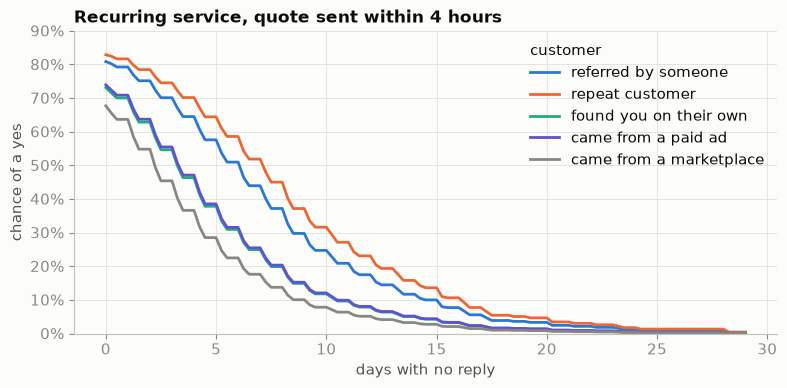

In [2]:
import figures
import style

style.apply()
figures.silence_by_customer(model)

In [3]:
explain(model, board.iloc[0]).to_frame()

,adds to the score
a typical quote starts at,0.7601
type of work: emergency job,0.5897
customer source: referred by someone,0.2834
quote sent after 4.0 hours,0.2009
no reply for 1.8 days,-0.2070
total,1.6271
chance of a yes (from the total),0.8358


## The whole scorecard

Every fact and the points it adds, for a yes and for "if it's a no, says so out loud". These are the
numbers the list is built from on this morning.

In [4]:
from quote_followup import artifacts

artifacts.scorecard(model)

,points towards a yes,points towards saying no out loud
fact,,
emergency job,0.6930,0.7261
one-off project,-0.4480,-0.8050
recurring service,0.3003,0.2400
came from a marketplace,-0.3115,-0.5882
found you on their own,-0.0514,-0.2287
came from a paid ad,-0.0092,-0.2559
referred by someone,0.3900,0.4760
repeat customer,0.5275,0.7579
each step slower in sending the quote,-0.2023,-0.2101


This customer came by referral, and referred customers who turn a quote down usually say so
(notebook 03). So nearly two days without a reply only nudges the chance down a little.

## What actually happened

In [5]:
with_outcomes(board, quotes)

,amount,days waiting,chance of yes,worth today,how it ended,reply came
quote_id,,,,,,
QU013118,1737.88,1.799,0.836,1452.470,accepted,2024-12-12 13:50:00
QU013170,2768.75,0.797,0.452,1250.706,accepted,2024-12-13 20:53:00
QU013126,13827.56,19.652,0.026,364.662,expired,NaT
QU013112,4021.24,15.632,0.056,227.012,expired,NaT
QU013138,233.33,3.806,0.657,153.192,declined,2024-12-12 14:40:00
QU013158,167.51,0.720,0.720,120.651,expired,NaT


The top two said yes that afternoon and the next evening. Calling the biggest quote first would have
meant a \$13.8k project that had been quiet for nearly three weeks; it expired. Calling the newest
first would have meant a \$168 quote; it expired too.

The third pick is that same \$13.8k quote at a 3% chance. It's there because 3% of \$13.8k is still
worth more than most small quotes. The list goes after dollars, so a big long shot can outrank a
small likely yes. An owner who would rather count yeses can order by chance instead.

## A morning where it gets it wrong

In [6]:
other_morning = pd.Timestamp("2024-12-17 08:00")
other_model = FollowUpModel(settings.model).fit(quotes, other_morning)
with_outcomes(followup_board(other_model, quotes, "SP0236", other_morning, 3), quotes)

,amount,days waiting,chance of yes,worth today,how it ended,reply came
quote_id,,,,,,
QU011549,5925.07,4.708,0.404,2393.359,accepted,2024-12-22 21:01:00
QU011550,3423.25,0.531,0.480,1642.167,expired,NaT
QU011507,5889.44,5.705,0.221,1298.944,expired,NaT
QU011528,2619.98,3.778,0.438,1148.141,accepted,2024-12-23 15:19:00
QU011523,6204.94,16.803,0.035,218.952,expired,NaT
QU011526,252.74,1.808,0.657,166.071,expired,NaT
QU011522,507.55,5.445,0.232,117.787,expired,NaT
QU011520,3155.72,28.583,0.015,46.275,expired,NaT


Second on the list was a \$3.4k project at 48%; it expired. A \$2.6k project at 44%, fourth, said
yes. When two quotes have nearly the same chance, which one comes through is close to a coin toss.

## Three weeks of the list, replayed

![The list replayed every four hours for three weeks](../assets/board.gif)

## What this does and doesn't show

- **It finds the quotes most likely to say yes. It doesn't prove a call changes anything.** The data
  has no record of follow-up calls, so some of these yeses would have come anyway. Skipping
  follow-ups on a random share of quotes for a few weeks would measure the real effect.
- **For putting quotes in order, the simple "days waiting × amount" list does as well** (notebook 05).
  The full model is there so the chance shown for each quote is right for that kind of quote, and
  so the reasons are real.
- **The data is synthetic.** The patterns here are the ones the data's creators built in.